## 합성곱 신경망(CNN)


In [2]:
import time
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST
from torchvision.transforms import v2

# 난수 시드를 고정한다.
SEED = 42
torch.manual_seed(SEED)


### CNN이란 무엇인가

이미지의 물체를 구분할 때는 경계선, 곡선, 무늬처럼 주변 픽셀들이 함께 만드는 모양이 중요하다. 이러한 작은 패턴을 조합하면 물체의 부분이나 전체 형태를 구분하는 데 도움이 된다.

CNN(합성곱 신경망)은 이미지의 작은 영역을 반복해서 계산하며, 분류에 필요한 패턴을 학습하는 신경망이다. 같은 계산을 이미지의 여러 위치에 적용하므로, 비슷한 패턴을 위치가 달라져도 찾아낼 수 있다.

여러 층을 거치면 앞 층에서 얻은 패턴들을 조합해 더 넓은 영역의 특징을 계산한다. 마지막 분류층은 이 특징들을 이용해 클래스별 점수를 만든다. 어떤 패턴에 반응할지는 학습 과정에서 가중치가 조정되면서 결정된다.

![입력 이미지에서 합성곱·풀링·분류층을 거쳐 클래스별 점수를 계산하는 CNN 개념도](images/cnn-overview.png)


### 손글씨 숫자 분류

손글씨 이미지의 픽셀값을 입력으로 받아 0~9 중 하나를 예측하는 문제다. CNN으로 선과 곡선 등의 특징을 추출해 숫자를 분류한다.

### MNIST 데이터 불러오기

한 사례는 손글씨 숫자를 담은 28×28 흑백 이미지다.

| 역할 | 데이터 | 의미 |
| --- | --- | --- |
| 입력 | 이미지의 픽셀값 | 위치별 밝기, 0~255 |
| 정답 | 숫자 번호 | 0~9의 정수 |

공식 학습 데이터는 60,000장, 테스트 데이터는 10,000장이다.
이미지는 CNN 입력 형태의 실수 텐서로 변환하고 픽셀값을 0~1로 맞춘다.


In [3]:
# 이미지를 꺼낼 때 적용할 변환을 순서대로 묶는다.
transform = v2.Compose([
    v2.ToImage(),  # 흑백 이미지를 (1, 28, 28) 형태의 이미지 텐서로 변환한다.
    v2.ToDtype(torch.float32, scale=True),  # 실수형으로 바꾸고 픽셀값을 0~1로 맞춘다.
])

# 공식 학습·테스트 데이터를 불러온다. 내려받은 데이터는 image_data에 보관한다.
mnist_train = MNIST(root="image_data", train=True, download=True, transform=transform)
mnist_test = MNIST(root="image_data", train=False, download=True, transform=transform)
classes = [str(number) for number in range(10)]
labels = mnist_train.targets.numpy()
print("공식 학습·테스트 이미지 수:", len(mnist_train), len(mnist_test))


100%|██████████| 9.91M/9.91M [00:04<00:00, 2.31MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 148kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.02MB/s]

공식 학습·테스트 이미지 수: 60000 10000


### 데이터 준비

실행 시간을 줄이기 위해 공식 학습 데이터 60,000장 중 학습 6,000장·검증 1,000장만 사용한다. 공식 테스트 데이터 10,000장에서도 테스트 1,000장만 선택한다.


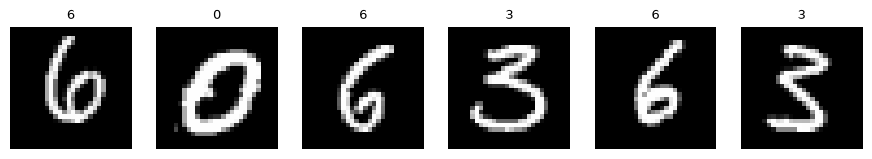

In [4]:
# 숫자 비율을 유지하며 학습용 인덱스를 뽑고, 남은 인덱스에서 검증용을 뽑는다.
idx_train, remaining = train_test_split(
    np.arange(len(mnist_train)), train_size=6000, stratify=labels, random_state=SEED,
)
idx_val, _ = train_test_split(remaining, train_size=1000, stratify=labels[remaining], random_state=SEED)

# 테스트용 인덱스는 공식 테스트 데이터에서 따로 선택한다.
idx_test, _ = train_test_split(
    np.arange(len(mnist_test)), train_size=1000,
    stratify=mnist_test.targets.numpy(), random_state=SEED,
)

# Subset은 선택한 인덱스의 이미지와 정답을 가져온다.
train_dataset = Subset(mnist_train, idx_train.tolist())
val_dataset = Subset(mnist_train, idx_val.tolist())
test_dataset = Subset(mnist_test, idx_test.tolist())

# 시각화: 학습 이미지 6장을 한 줄에 그리고 정답 숫자을 제목으로 표시한다.
fig, axes = plt.subplots(1, 6, figsize=(11, 2))
for i, ax in enumerate(axes):
    image, label = train_dataset[i]
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)  # 채널 축을 골라 28×28 밝기 표를 그린다.
    ax.set_title(classes[label], fontsize=9)
    ax.axis("off")
plt.show()


### 이미지를 배치로 준비하기

배치는 한 번에 처리할 이미지 묶음이다. PyTorch에서 이미지 배치는 `(배치 크기, 채널 수, 높이, 너비)` 순서로 구성한다.

채널은 밝기나 색상별 값을 담은 표 한 장으로, 흑백은 1개, RGB 컬러는 3개를 사용한다. MNIST 이미지 128장을 묶으면 모양은 `(128, 1, 28, 28)`이다.


In [5]:
# 평가용 이미지를 순서대로 128장씩 묶는다. 학습용 배치는 학습 함수에서 섞는다.
train_eval_loader = DataLoader(train_dataset, batch_size=128)
val_loader = DataLoader(val_dataset, batch_size=128)
test_loader = DataLoader(test_dataset, batch_size=128)

# 첫 배치를 꺼내 이미지와 정답 텐서의 모양을 확인한다.
images, targets = next(iter(train_eval_loader))
print("한 배치의 이미지·정답:", images.shape, targets.shape)


한 배치의 이미지·정답: torch.Size([128, 1, 28, 28]) torch.Size([128])


## 합성곱과 풀링

| 연산 | 역할 |
| --- | --- |
| 합성곱 | 특징 추출: 학습한 필터로 경계·무늬 등의 패턴에 대한 반응을 계산한다 |
| 풀링 | 공간 크기 축소: 영역별 대표값을 남겨 특성 맵을 압축하고 계산량을 줄인다 |

### 합성곱: 특징 추출

합성곱은 이미지의 작은 영역에 가중치를 곱하고 더하는 계산이다. 이 가중치 묶음을 필터(커널)라고 한다. 예를 들어 3×3 필터는 주변 픽셀 9개에 각각 가중치를 곱하고, 그 값을 더해 출력 한 칸을 만든다.

같은 필터를 여러 위치로 이동하며 계산한 결과가 특성 맵이다. 필터의 가중치는 학습으로 조정되며, 경계나 무늬처럼 분류에 유용한 패턴에 반응하도록 학습된다.

필터가 한 번에 이동하는 간격은 스트라이드다. 패딩은 입력 가장자리에 값을 덧대어 출력 크기를 조절하는 방법이며, 보통 0으로 채운다. 예를 들어 3×3 필터를 한 칸씩 이동할 때, 가장자리에 한 겹의 패딩을 추가하면 출력의 높이와 너비를 입력과 같게 유지할 수 있다.

### 풀링: 특성 맵 압축

풀링은 작은 영역의 여러 값을 하나의 대표값으로 요약하는 연산이다. 보통 공간 크기를 줄여 다음 층의 계산량을 줄이며, 세부 위치 정보는 일부 줄어든다. 대표적인 방식으로 영역의 최댓값을 남기는 최대 풀링, 평균값을 구하는 평균 풀링 등이 있다.

이 실습에서는 2×2 영역을 두 칸씩 이동하는 최대 풀링을 사용한다. 네 값 중 가장 큰 값 하나를 남기며, 각 채널에 따로 적용하므로 채널 수는 유지된다. 최대 풀링에는 학습할 가중치가 없다.


### 합성곱과 풀링 예제

3×3 입력에 2×2 필터를 한 칸씩 이동하며 계산한다. 패딩을 사용하지 않아 필터를 놓을 수 있는 위치는 네 곳이고, 출력은 2×2다.
주황색 영역의 값과 필터 값을 같은 위치끼리 곱한 뒤 더하면 오른쪽 위 출력 -1이 나온다. 최대 풀링은 완성된 출력 네 값 중 가장 큰 값 하나를 남긴다.

![3×3 입력과 2×2 필터의 합성곱 계산 및 최대 풀링 결과](images/cnn-convolution-pooling.png)


## CNN 구성

### 특징 추출과 분류

이미지 분류용 CNN은 이미지에서 특징을 추출하는 부분과, 추출한 특징으로 클래스별 점수를 계산하는 부분으로 구성한다.

특징 추출 부분에서는 합성곱으로 패턴을 계산하고 활성화 함수를 적용한다. 필요에 따라 풀링으로 공간 크기를 줄이며, 이러한 층을 쌓아 앞에서 얻은 특징들을 결합한다. 분류 부분에서는 추출한 특징을 모아 클래스별 점수를 계산한다. 층의 수·필터 수·활성화 함수·풀링 사용 여부는 문제에 맞게 정한다.

### 여러 채널의 특징 결합

합성곱 필터 하나가 출력 특성 맵 하나를 만들므로, 필터 수가 출력 채널 수가 된다. 기본 합성곱에서 각 필터는 모든 입력 채널을 함께 읽어 새로운 특징을 계산한다.

이 예제에서는 합성곱·ReLU·최대 풀링으로 이루어진 블록을 두 번 쌓는다. 두 합성곱 모두 3×3 필터를 사용하며, 필터 수는 각각 32개와 64개로 정한다.

첫 합성곱은 흑백 채널 1개를 받아 특성 맵 32개를 만든다. 두 번째 합성곱의 필터 하나는 입력 채널 32개에서 계산한 값을 더해 특성 맵 하나를 만든다. 이런 필터 64개가 출력 채널 64개를 만든다.

마지막 풀링의 결과를 Flatten으로 펼친 뒤, 노드 128개의 은닉층과 ReLU를 거쳐 노드 10개의 출력층에 전달한다. 출력층은 10개 숫자의 점수인 로짓을 반환한다.

![이번 예제의 CNN 구조: 층별 출력 모양과 두 번째 합성곱의 채널 결합](images/cnn-channel-shapes.png)


In [7]:
def make_cnn(channels=32, hidden_units=128):
    # Sequential에 나열한 층을 앞에서부터 순서대로 적용한다.
    return nn.Sequential(
        # 특징 추출: 3×3 합성곱과 2×2 최대 풀링을 두 번 적용한다.
        # Conv2d: 높이·너비의 두 공간 축에서 합성곱을 계산하는 층. 필터 가중치는 학습으로 갱신된다.
        # channels=32: 필터 32개로 출력 채널 32개를 만든다. 기본 stride=1, padding=0.
        nn.Conv2d(in_channels=1, out_channels=channels, kernel_size=3),
        nn.ReLU(),  # 음수는 0으로 바꾸고 양수는 유지한다.
        nn.MaxPool2d(2),  # 2×2 영역의 최댓값을 남긴다. 기본 stride는 2다.
        nn.Conv2d(in_channels=channels, out_channels=channels * 2, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # 분류: 펼친 특징 → hidden_units개의 은닉 값 → 숫자 점수 10개.
        nn.Flatten(),  # 배치 축을 남기고 채널·높이·너비를 하나로 펼친다.
        # 입력 크기나 합성곱·풀링 구조를 바꾸면 Linear의 입력 크기도 다시 확인한다.
        nn.Linear(channels * 2 * 5 * 5, hidden_units),  # 펼친 입력값 개수 → 은닉 노드 수.
        nn.ReLU(),
        nn.Linear(hidden_units, 10),
    )


### 층별 출력 크기 확인

`Linear`의 입력 크기는 합성곱·풀링으로 얻은 특징의 개수에 맞춰야 한다. 모델을 구성할 때 예시 입력으로 출력 크기를 미리 확인할 수 있다. 여기서는 층별 출력 크기를 확인해 설정한 입력 크기가 맞는지 점검한다.

패딩 없이 3×3 필터를 한 칸씩 이동하면 가로·세로가 각각 2칸 줄어든다. 이 예제에서는 28×28 → 26×26, 13×13 → 11×11이 된다.

2×2 최대 풀링을 두 칸씩 이동하면 가로·세로가 절반으로 줄고, 홀수는 내림한다. 26×26 → 13×13, 11×11 → 5×5가 된다. 풀링과 ReLU는 채널 수를 유지한다.

Flatten은 이미지마다 특성 맵을 한 줄로 펼친다. 기본 설정에서는 5×5 특성 맵 64개가 1,600개의 값이 되어 Linear 층에 전달된다.


In [8]:
model = make_cnn()

# 28×28 흑백 이미지 2장과 같은 모양의 예시 입력을 만든다.
sample = torch.zeros(2, 1, 28, 28)

# 층을 하나씩 통과시키며 출력 모양과 해당 층의 파라미터 수를 확인한다.
for layer in model:
    sample = layer(sample)
    print(type(layer).__name__, tuple(sample.shape), "파라미터:", sum(p.numel() for p in layer.parameters()))
print("전체 파라미터:", sum(p.numel() for p in model.parameters()))


Conv2d (2, 32, 26, 26) 파라미터: 320
ReLU (2, 32, 26, 26) 파라미터: 0
MaxPool2d (2, 32, 13, 13) 파라미터: 0
Conv2d (2, 64, 11, 11) 파라미터: 18496
ReLU (2, 64, 11, 11) 파라미터: 0
MaxPool2d (2, 64, 5, 5) 파라미터: 0
Flatten (2, 1600) 파라미터: 0
Linear (2, 128) 파라미터: 204928
ReLU (2, 128) 파라미터: 0
Linear (2, 10) 파라미터: 1290
전체 파라미터: 225034


## CNN 학습

### 학습 조건

배치 크기 64, Adam 학습률 0.001, 5에포크로 학습한다.


### 한 에포크 학습

학습 데이터를 배치 단위로 한 번 처리하며, 교차 엔트로피 손실을 이용해 가중치를 갱신한다. 한 에포크의 평균 손실과 정확도를 계산한다.


In [9]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:  # 배치를 하나씩 꺼낸다.

        # 순전파: 숫자별 점수를 예측하고 정답과의 손실을 계산한다.
        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, labels)

        # 이전 기울기를 비우고, 역전파로 구한 기울기를 사용해 가중치를 갱신한다.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # 배치 평균 손실에 이미지 수를 곱해 누적하고, 맞힌 이미지 수도 센다.
        loss_sum += loss.item() * len(labels)

        # argmax(dim=1): 이미지마다 점수가 가장 큰 숫자 번호를 고른다.
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return loss_sum / count, correct / count


### 모델 평가

가중치를 갱신하지 않고, 주어진 데이터의 평균 손실과 정확도를 계산한다.


In [10]:
# 평가 중에는 기울기를 계산하지 않는다.
@torch.no_grad()
def evaluate_classifier(model, loader):
    # 모델을 평가 모드로 전환한다.
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:
        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, labels)
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)

    # 전체 이미지 기준의 평균 손실과 정확도를 반환한다.
    return loss_sum / count, correct / count


### 반복 학습과 기록

에포크별 학습·검증 결과를 기록하고, 학습이 끝나면 검증 손실이 가장 작았던 가중치로 복원한다.


In [11]:
def fit_classifier(model, train_loader, train_eval_loader, val_loader, epochs=5, lr=0.001):
    # 모델 가중치를 갱신할 Adam 옵티마이저를 준비한다.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    best_loss, best_state = float("inf"), None
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)

        # 에포크가 끝난 동일한 가중치로 학습·검증 손실을 평가해 곡선에 기록한다.
        train_eval_loss, _ = evaluate_classifier(model, train_eval_loader)
        val_loss, val_acc = evaluate_classifier(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": train_loss,
                        "train_eval_loss": train_eval_loss, "val_loss": val_loss, "train_accuracy": train_acc, "val_accuracy": val_acc})

        # 검증 손실이 가장 작은 시점의 가중치를 별도로 복사해 둔다.
        if val_loss < best_loss:
            best_loss, best_state = val_loss, deepcopy(model.state_dict())
        print(f"epoch={epoch+1} train_loss={train_loss:.3f} val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    # 가장 좋은 검증 손실을 얻었던 가중치로 복원한다.
    model.load_state_dict(best_state)
    return pd.DataFrame(history)


### 학습과 결과 기록

설정한 조건으로 모델을 학습하고, 학습 기록과 검증 결과·파라미터 수·소요 시간을 정리한다.


In [13]:
# 기본 CNN과 필터 수 변경 실험에 같은 학습 설정을 사용한다.
CONFIG = {"seed": SEED, "epochs": 5, "learning_rate": 0.001, "batch_size": 64, "channels": 32, "hidden_units": 128}

def train_and_evaluate(name, model, train_dataset, train_eval_loader, val_loader):

    # 배치에 다양한 숫자가 섞이도록 순서를 섞어, 데이터 나열 순서에 따른 학습 편향을 줄인다.
    # 같은 시드로 로더를 만들어 실험마다 같은 배치 순서를 사용한다.
    loader = DataLoader(
        train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
        generator=torch.Generator().manual_seed(CONFIG["seed"]),
    )

    # 학습·평가에 걸린 시간을 측정한다.
    start = time.perf_counter()
    trace = fit_classifier(
        model, loader, train_eval_loader, val_loader,
        epochs=CONFIG["epochs"], lr=CONFIG["learning_rate"],
    )
    seconds = time.perf_counter() - start
    val_loss, val_accuracy = evaluate_classifier(model, val_loader)

    # 비교 표에 넣을 모델 크기, 검증 결과, 소요 시간을 묶는다.
    row = {"condition": name, "parameters": sum(p.numel() for p in model.parameters()),
           "val_loss": val_loss, "val_accuracy": val_accuracy, "seconds": seconds}
    return trace, row


### CNN 학습 결과

CNN을 학습하고 검증 손실·정확도·파라미터 수·소요 시간을 확인한다.


In [14]:
# 난수 시드를 맞추고 CNN을 직접 만든다.
torch.manual_seed(CONFIG["seed"])
cnn = make_cnn(CONFIG["channels"], CONFIG["hidden_units"])

# 모델과 학습·평가 데이터를 전달해 학습한다.
cnn_history, cnn_result = train_and_evaluate(
    "CNN", cnn, train_dataset, train_eval_loader, val_loader,
)

# 결과 표: 검증 손실·정확도·파라미터 수·소요 시간.
display(pd.DataFrame([cnn_result]))


epoch=1 train_loss=0.887 val_loss=0.360 val_acc=0.898
epoch=2 train_loss=0.235 val_loss=0.204 val_acc=0.942
epoch=3 train_loss=0.138 val_loss=0.161 val_acc=0.948
epoch=4 train_loss=0.103 val_loss=0.134 val_acc=0.957
epoch=5 train_loss=0.087 val_loss=0.123 val_acc=0.960


,condition,parameters,val_loss,val_accuracy,seconds
0,CNN,225034,0.123251,0.96,36.484887


### 학습 곡선 읽기

각 에포크가 끝난 모델의 학습·검증 손실을 표시한다. CNN의 손실 변화와 학습·검증 간격을 살펴본다.


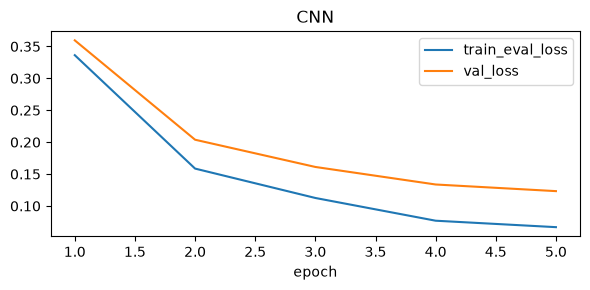

In [15]:
# 시각화: 에포크에 따른 학습 손실과 검증 손실을 같은 그래프에 그린다.
fig, ax = plt.subplots(figsize=(6, 3))
cnn_history.plot(x="epoch", y=["train_eval_loss", "val_loss"], ax=ax, title="CNN")
plt.tight_layout()
plt.show()


## 특성 맵 관찰

### 합성곱과 풀링의 출력 읽기

같은 숫자의 이미지 세 장을 CNN에 넣고 두 합성곱의 ReLU 출력과 풀링 출력을 표시한다.
특성 맵의 밝은 부분은 해당 필터가 강하게 반응한 위치다. 같은 층의 같은 채널에서 세 이미지의 반응 위치와 모양을 비교한다.
풀링은 채널을 유지하면서 공간 크기를 줄인다. 두 번째 합성곱은 앞 층의 모든 채널을 조합해 새로운 특징을 만든다.

각 합성곱과 그 뒤 풀링의 그림은 세 이미지에 동일한 색 범위를 사용한다. 첫 번째·두 번째 합성곱은 각각의 색 범위에서 반응 위치와 모양을 관찰한다.


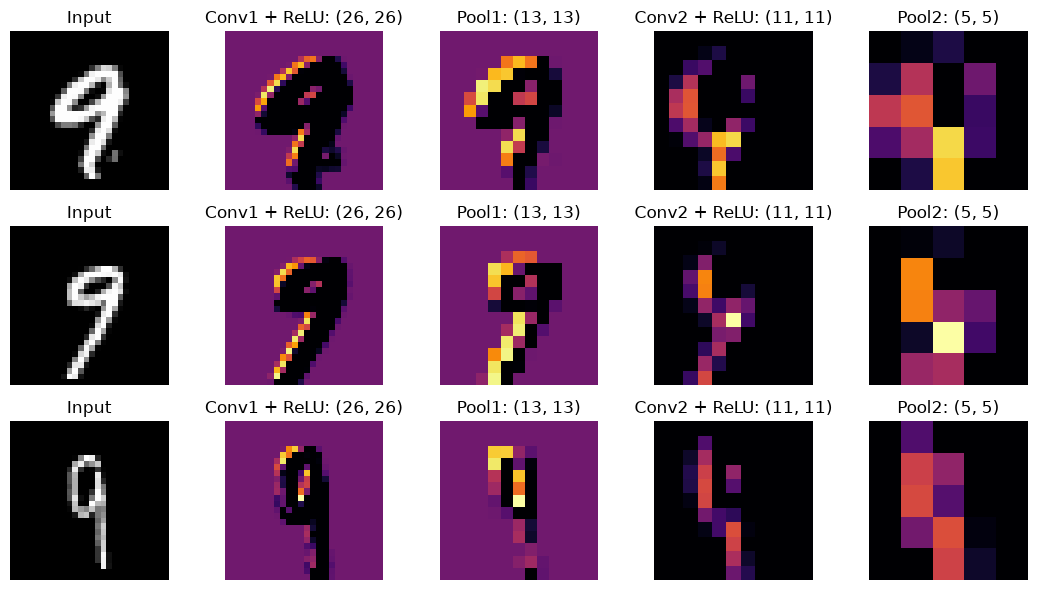

In [22]:
# 특성 맵과 오분류 관찰에 사용할 검증 이미지를 한 묶음으로 가져온다.
val_images, val_labels = next(iter(DataLoader(val_dataset, batch_size=len(val_dataset))))
cnn.eval()
positions = torch.where(val_labels == 9)[0][:3]  # 손글씨 숫자 9
FEATURE_CHANNEL = 31  # 각 층에서 표시할 채널 번호.

# Sequential의 층 번호로 관찰할 ReLU·풀링 출력을 지정한다.
stage_names = {1: "Conv1 + ReLU", 2: "Pool1", 4: "Conv2 + ReLU", 5: "Pool2"}
maps = []

# 계산: 선택한 이미지 3장을 통과시키며 중간 특성 맵을 저장한다.
with torch.no_grad():
    values = val_images[positions]
    for index, layer in enumerate(cnn):
        values = layer(values)
        if index in stage_names:
            maps.append((stage_names[index], values))

# 같은 합성곱·풀링 묶음은 세 이미지에 공통된 색 범위를 사용한다.
color_max = [max(maps[i][1][:, FEATURE_CHANNEL].max().item(), 1e-8) for i in (0, 2)]

# 시각화: 행은 이미지, 열은 원본과 네 단계의 특성 맵이다.
fig, axes = plt.subplots(len(positions), 5, figsize=(11, 6), squeeze=False)
for row, position in enumerate(positions):
    axes[row, 0].imshow(val_images[position, 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title("Input")
    for col, (title, values) in enumerate(maps, start=1):
        axes[row, col].imshow(
            values[row, FEATURE_CHANNEL], cmap="inferno",
            vmin=0, vmax=color_max[(col - 1) // 2],  # 합성곱과 바로 뒤 풀링의 색 범위를 맞춘다.
        )
        axes[row, col].set_title(f"{title}: {tuple(values.shape[-2:])}")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()


## 필터 수에 따른 모델 비교

### 필터 수 바꾸기

두 합성곱의 채널 수를 32·64에서 16·32로 바꾸어 학습한다. 데이터·학습률·에포크는 기본 CNN과 같게 둔다.
첫 합성곱의 필터 수를 64개로 바꾸면 두 층의 필터 수는 64·128개가 된다.
혼동행렬과 최종 평가에는 기본 CNN을 사용한다.


In [23]:
# 첫 합성곱의 필터 수를 바꿔 새 CNN을 학습한다. 두 번째 층은 이 값의 두 배다.
EXPERIMENT_CHANNELS = 16
torch.manual_seed(CONFIG["seed"])
changed_model = make_cnn(EXPERIMENT_CHANNELS, CONFIG["hidden_units"])

# 같은 데이터와 학습 조건으로 필터 수를 바꾼 모델을 학습한다.
changed_history, changed_row = train_and_evaluate(
    f"CNN_channels_{EXPERIMENT_CHANNELS}", changed_model,
    train_dataset, train_eval_loader, val_loader,
)

# 결과 표: 기본 CNN과 필터 수를 바꾼 CNN을 비교한다.
structure_comparison = pd.DataFrame([cnn_result, changed_row])
display(structure_comparison)


epoch=1 train_loss=1.005 val_loss=0.434 val_acc=0.866
epoch=2 train_loss=0.287 val_loss=0.270 val_acc=0.918
epoch=3 train_loss=0.183 val_loss=0.209 val_acc=0.932
epoch=4 train_loss=0.141 val_loss=0.166 val_acc=0.944
epoch=5 train_loss=0.116 val_loss=0.144 val_acc=0.951


,condition,parameters,val_loss,val_accuracy,seconds
0,CNN,225034,0.123251,0.960,36.484887
1,CNN_channels_16,108618,0.144088,0.951,26.731001


## 모델 평가

### 혼동행렬과 오분류 이미지

기본 CNN이 어떤 숫자을 서로 혼동하는지 오분류 이미지와 함께 확인한다.


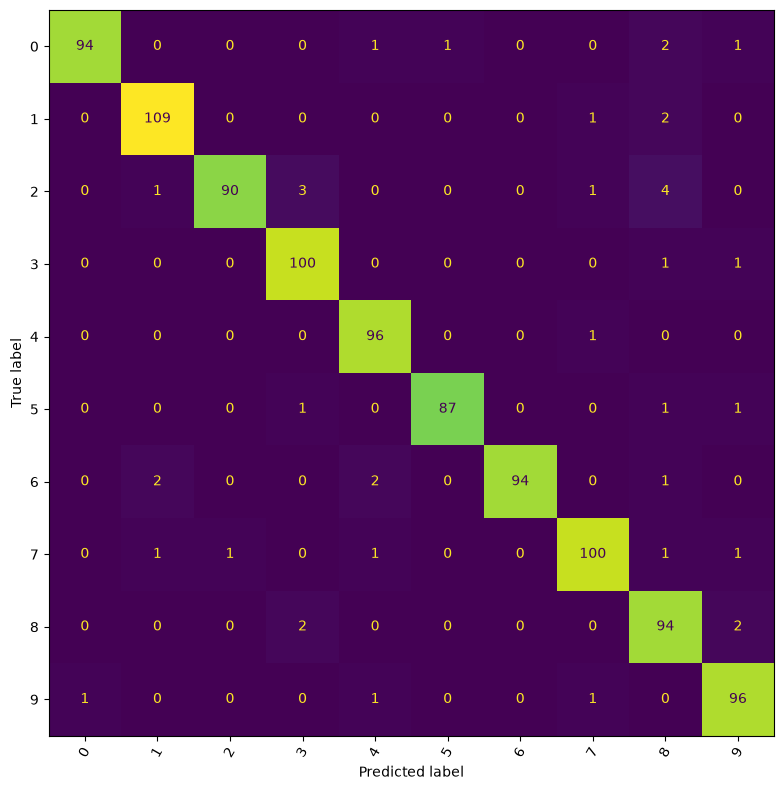

검증 오분류 수: 40
가장 많은 혼동: 2 → 8 (4장)


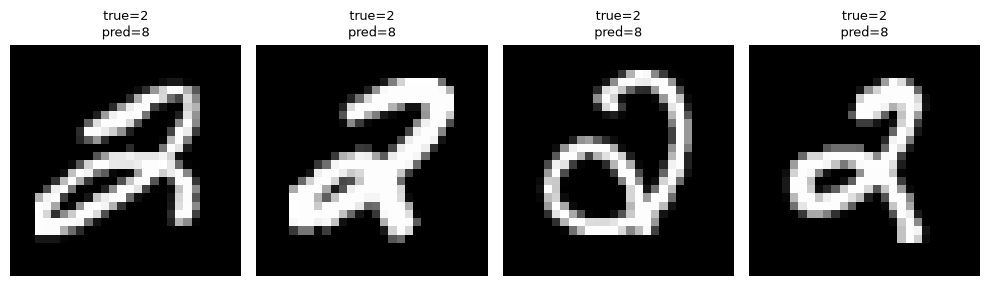

In [24]:
# 예측: 검증 배치별 예측 숫자을 원래 이미지 순서대로 이어 붙인다.
cnn.eval()
with torch.no_grad():
    pred = torch.cat([cnn(xb).argmax(1) for xb, _ in val_loader]).numpy()

# 시각화: 실제 숫자을 행, 예측 숫자을 열로 하는 혼동행렬을 그린다.
confusion = confusion_matrix(val_labels.numpy(), pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion, display_labels=classes).plot(ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout()
plt.show()

# 분석: 틀린 이미지 중 가장 많이 혼동한 실제 숫자 → 예측 숫자 조합을 찾는다.
wrong_positions = np.flatnonzero(pred != val_labels.numpy())
print("검증 오분류 수:", len(wrong_positions))
if len(wrong_positions):
    off_diagonal = confusion.copy()
    np.fill_diagonal(off_diagonal, 0)  # 맞힌 사례를 제외하고 가장 큰 혼동을 찾는다.

    # 최댓값의 위치를 실제 숫자의 행, 예측 숫자의 열로 변환한다.
    actual_class, predicted_class = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    chosen = np.flatnonzero(
        (val_labels.numpy() == actual_class) & (pred == predicted_class)
    )[:6]
    print(f"가장 많은 혼동: {classes[actual_class]} → {classes[predicted_class]} "
          f"({confusion[actual_class, predicted_class]}장)")

    # 시각화: 해당 조합으로 틀린 이미지를 최대 6장 표시한다.
    fig, axes = plt.subplots(1, len(chosen), figsize=(2.5 * len(chosen), 3), squeeze=False)
    for ax, index in zip(axes.ravel(), chosen):
        ax.imshow(val_images[index, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"true={classes[val_labels[index]]}\npred={classes[pred[index]]}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("검증 이미지에서 오분류가 없습니다.")


### 최종 테스트

기본 CNN의 학습·테스트 손실과 정확도를 비교한다.


In [25]:
# 최종 평가: 기본 CNN의 학습·테스트 손실과 정확도를 같은 표에 정리한다.
final_results = []
for split, loader in [("train", train_eval_loader), ("test", test_loader)]:
    loss, accuracy = evaluate_classifier(cnn, loader)
    final_results.append({"split": split, "loss": loss, "accuracy": accuracy})
print("모델: CNN")
display(pd.DataFrame(final_results))


모델: CNN


,split,loss,accuracy
0,train,0.066800,0.981167
1,test,0.095038,0.969000


## 연습문제: Fashion-MNIST 하이퍼파라미터 실험

### Fashion-MNIST 데이터 불러오기

Fashion-MNIST는 의류·신발·가방의 28×28 흑백 이미지이며, 정답은 10개 품목 중 하나다. 공식 학습 데이터는 60,000장, 테스트 데이터는 10,000장이다.
이미지는 CNN 입력 모양에 맞추고 픽셀값을 0~1로 변환한다.


In [26]:
from torchvision.datasets import FashionMNIST

# 실습용 의류 이미지를 불러오고, 같은 변환을 적용한다.
fashion_train = FashionMNIST(root="image_data", train=True, download=True, transform=transform)
fashion_test = FashionMNIST(root="image_data", train=False, download=True, transform=transform)
exercise_classes = fashion_train.classes


100%|██████████| 26.4M/26.4M [00:05<00:00, 5.07MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 111kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.1MB/s]


### 실습 데이터 준비

학습 6,000장·검증 1,000장·테스트 1,000장을 품목별 비율과 난수 시드 42를 유지해 선택한다. 모든 실험에 같은 분할과 전처리를 사용한다.


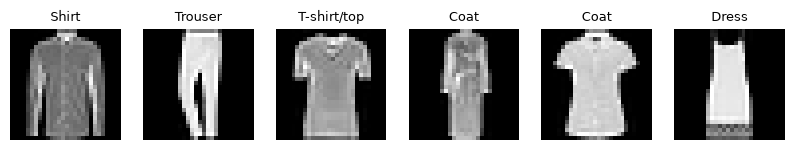

학습·검증·테스트 이미지 수: 6000 1000 1000


In [27]:
# 품목별 비율을 유지하며 학습·검증·테스트 인덱스를 선택한다.
exercise_labels = fashion_train.targets.numpy()
exercise_train_idx, exercise_remaining = train_test_split(
    np.arange(len(fashion_train)), train_size=6000, stratify=exercise_labels, random_state=SEED,
)
exercise_val_idx, _ = train_test_split(
    exercise_remaining, train_size=1000, stratify=exercise_labels[exercise_remaining], random_state=SEED,
)
exercise_test_idx, _ = train_test_split(
    np.arange(len(fashion_test)), train_size=1000,
    stratify=fashion_test.targets.numpy(), random_state=SEED,
)
exercise_train = Subset(fashion_train, exercise_train_idx.tolist())
exercise_val = Subset(fashion_train, exercise_val_idx.tolist())
exercise_test = Subset(fashion_test, exercise_test_idx.tolist())

# 학습용 배치는 섞고, 평가용 배치는 원래 순서대로 가져온다.
def make_exercise_train_loader(batch_size=64):
    # 실험마다 지정한 배치 크기로 새 로더를 만들고, 이미지 셔플 시드를 맞춘다.
    return DataLoader(
        exercise_train, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

exercise_train_loader = make_exercise_train_loader()
exercise_train_eval = DataLoader(exercise_train, batch_size=128)
exercise_val_loader = DataLoader(exercise_val, batch_size=128)
exercise_test_loader = DataLoader(exercise_test, batch_size=128)

# 시각화: 의류 이미지 6장과 정답 품목를 확인한다.
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    exercise_image, exercise_label = exercise_train[i]
    ax.imshow(exercise_image[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(exercise_classes[exercise_label], fontsize=9)
    ax.axis("off")
plt.show()
print("학습·검증·테스트 이미지 수:", len(exercise_train), len(exercise_val), len(exercise_test))


### 직접 작성하기: 하이퍼파라미터 실험

준비된 Fashion-MNIST 데이터를 활용해 CNN을 학습해 보자. 코드에서 바꿀 수 있는 하이퍼파라미터가 무엇인지 확인하고, 여러 값으로 실험해 보자.

한 번에 한 항목씩 바꾸고, 매 실험마다 모델을 새로 학습한다. 데이터 분할과 난수 시드는 같게 유지한다.

실험별 검증 손실·정확도와 학습 곡선을 비교하며 결과가 어떻게 달라지는지 살펴보자. 검증 손실로 최종 모델을 선택하고 테스트 데이터에서 한 번 평가한다.
